<h1>Full Michaelis-Menten System</h1>

<h3>Python code 2-07 accompanying <i>Molecular Machines</i></h3> 

<p>G. Woehlke 2011 ff (converted from Wolfram Mathematica, aided by A.I.)</p>

<h3>Kinetic scheme: </h3> <img src="2-07_MichaelisMenten_ExtendedSystem.png" width="466"> 

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

<p>In the system we have: 
<ul><li>7 ODEs (cE, cES, cEG, cEF, cS, cG, cF)</li>
<li>10 reaction rates (r1–r10)</li>
<li>initial conditions</li>
<li>a set of parameters</li>
<li>a plotting routine.</li></ul></p>

<h3>ODE system</h3>
<p>r1 to r10 collect rate constants with their relevant concentration dependendies</p>

In [2]:
def system(t, y, k):
    cE, cES, cEG, cEF, cS, cG, cF = y
    k12, k21, k23, k32, k35, k53, k24, k42, k45, k54 = k

    # reaction rates
    r1 = k12 * cE * cS
    r2 = k21 * cES
    r3 = k23 * cES
    r4 = k32 * cEG * cF
    r5 = k35 * cEG
    r6 = k53 * cE * cG
    r7 = k24 * cES
    r8 = k42 * cEF * cG
    r9 = k45 * cEF
    r10 = k54 * cE * cF

    # ODEs
    dcE  = -r1 + r2 + r5 - r6 + r9 - r10
    dcES =  r1 - r2 - r3 + r4 - r7 + r8
    dcEG =  r3 - r4 - r5 + r6
    dcEF =  r7 - r8 - r9 + r10
    dcS  = -r1 + r2
    dcG  =  r5 - r6 + r7 - r8
    dcF  =  r3 - r4 + r9 - r10

    return [dcE, dcES, dcEG, dcEF, dcS, dcG, dcF]

<a name='init' />
<h3>Initial conditions</h3>
<h4> <span style="color:darkblue">Change and play!</span></h4>
<p>Default: $cE[0] = 0.1,
cES[0] = 0.,
cEG[0] = 0.,
cEF[0] = 0.,
cS[0] = 2.9,
cG[0] = 0.0,
cF[0] = 0.1$
</p>

In [3]:
# Initial concentrations
y0 = [0.1, 0.0, 0.0, 0.0, 2.9, 0.0, 0.1]

<a name='params' />
<h3>Parameters</h3>
<h4><span style="color:darkblue">Change and play!</span></h4>
<p>  Default: $\text{k12}\to 2.,\text{k21}\to 0.5,\text{k23}\to 10.,\text{k32}\to 0.25,\text{k35}\to 5.,\text{k53}\to 5.,\text{k24}\to 10.,\text{k42}\to 2.5,\text{k45}\to 5.,\text{k54}\to 5.$</p>

In [4]:
# Rate constants
k = [2.0, 0.25, 10., 0.25, 5., 5., 10., 2.5, 5., 5.]

<h3>Solve ODE</h3>
<p> Using <i>SciPy</i> numerical integration method</p>

In [5]:
t_span = (0, 10)   # tEnd = 10
t_eval = np.linspace(0, 10, 500)

sol = solve_ivp(system, t_span, y0, args=(k,), t_eval=t_eval)

<h3>Plot</h3>
<p> Using <i>MatPlotLib</i> method</p>

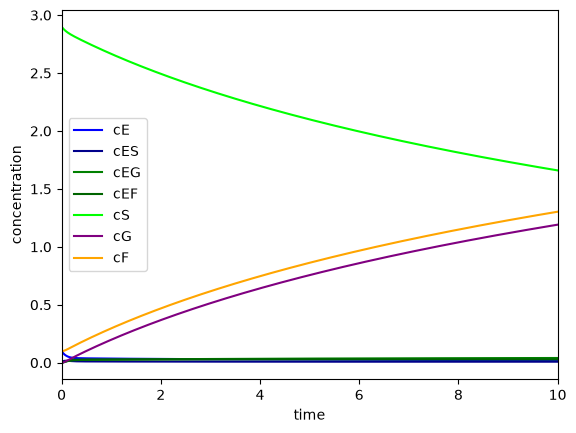

In [6]:
labels = ["cE", "cES", "cEG", "cEF", "cS", "cG", "cF"]
colors = ["blue", "darkblue", "green", "darkgreen", "lime", "purple", "orange"]

for i in range(7):
    plt.plot(sol.t, sol.y[i], label=labels[i], color=colors[i])

plt.xlabel("time")
plt.ylabel("concentration")
plt.legend()
plt.xlim(0, 10)
plt.show()

<h3>Detailed logarithmic plots</h3>
<p>Double-logarithmic plot for each component</p>

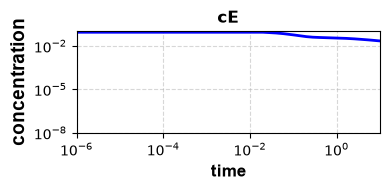

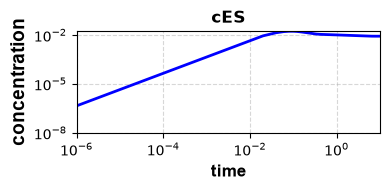

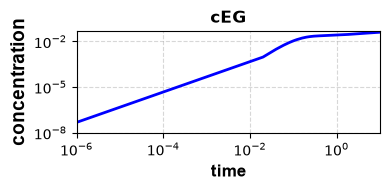

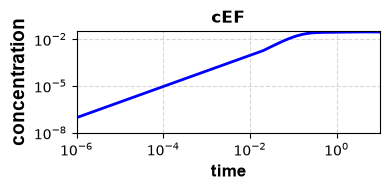

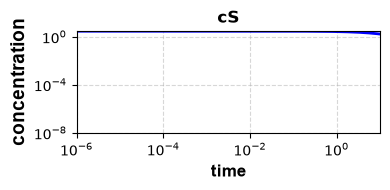

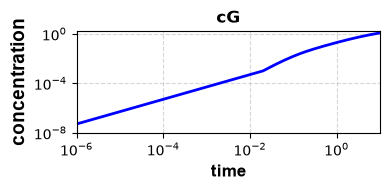

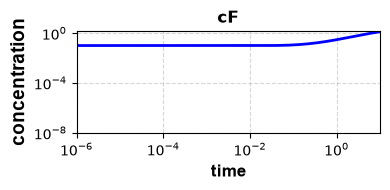

In [7]:
import matplotlib.pyplot as plt

labels = ["cE", "cES", "cEG", "cEF", "cS", "cG", "cF"]

for i, label in enumerate(labels):
    plt.figure(figsize=(4, 2))  # AspectRatio ~ 0.5

    plt.loglog(sol.t, sol.y[i], color="blue", linewidth=2)

    plt.xlabel("time", fontweight="bold", fontsize=12, family="Arial")
    plt.ylabel("concentration", fontweight="bold", fontsize=14, family="Arial")

    plt.title(label, fontweight="bold", fontsize=12)

    plt.xlim(left=1e-6, right=sol.t[-1])  # avoid log(0)
    plt.ylim(bottom=1e-8)  # avoid log(0)

    plt.grid(True, which="both", ls="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

<h3>Figure legend </h3>
<p>Concentration traces of the (original) Michaelis-Menten integrated system. Each <span style="color:blue">sub-plot</span> shows the logarithm of the concentration of each intermediate. Kinetic scheme: </p>
<img src="2-07_MichaelisMenten_ExtendedSystem.png" width="466"> 